# Uber Ride Analysis (2016)

End-to-end data science walkthrough of the *My Uber Drives - 2016* trip log: data preprocessing, exploratory data analysis (ride patterns, peak hours, fare trends, anomalies) and a daily ride-demand forecasting model.

All reusable logic lives in `src/uber_analysis/`; this notebook calls it step by step and explains the results.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from uber_analysis.preprocessing import load_raw_data, clean_data, daily_demand, FARE_RATES
from uber_analysis import visualization as viz
from uber_analysis.forecasting import run_forecasting, miles_regression_check, FEATURES

FIG = ROOT / 'reports' / 'figures'
def show(path):
    from IPython.display import Image, display
    display(Image(filename=str(path)))

## 1. The raw dataset

One person's Uber trips in 2016: start/end time, category (Business/Personal), start and stop location, miles, and trip purpose.

In [2]:
raw = load_raw_data(ROOT / 'data' / 'uber_drives_2016.csv')
print(raw.shape)
raw.head()

(1156, 7)


,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit


In [3]:
raw.tail(3)  # note the 'Totals' summary row at the end

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site
1155,Totals,NaN,NaN,NaN,NaN,12204.7,NaN


In [4]:
raw.isna().sum()

START_DATE*      0
END_DATE*        1
CATEGORY*        1
START*           1
STOP*            1
MILES*           0
PURPOSE*       503
dtype: int64

## 2. Preprocessing

1. Remove the `Totals` footer row.
2. Parse dates with an explicit `%m/%d/%Y %H:%M` format.
3. Drop exact duplicates.
4. Fill missing `purpose` with **Unspecified** (dropping would lose 43% of trips).
5. Fix the `Kar?chi` encoding error.
6. Remove trips with zero/negative duration.
7. Engineer features: hour, weekday, month, time of day, duration, speed, round trip, distance band, estimated fare.
8. **Flag** (not drop) outliers: very long trips (IQR rule) and speeds > 80 mph.

In [5]:
df, log = clean_data(raw)
pd.Series(log, name='rows')

raw_rows                         1156
totals_rows_removed                 1
unparseable_dates_removed           0
duplicates_removed                  1
purpose_filled_unspecified        502
non_positive_duration_removed       4
long_trip_outliers_flagged         46
speed_anomalies_flagged            19
clean_rows                       1150
Name: rows, dtype: int64

In [6]:
df[['start_time','category','start_location','stop_location','miles','purpose',
    'duration_min','speed_mph','hour','weekday','estimated_fare']].head()

,start_time,category,start_location,stop_location,miles,purpose,duration_min,speed_mph,hour,weekday,estimated_fare
0,2016-01-01 21:11:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6.0,51.000000,21,Friday,9.8
1,2016-01-02 01:25:00,Business,Fort Pierce,Fort Pierce,5.0,Unspecified,12.0,25.000000,1,Saturday,10.9
2,2016-01-02 20:25:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13.0,22.153846,20,Saturday,10.9
3,2016-01-05 17:31:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14.0,20.142857,17,Tuesday,11.0
4,2016-01-06 14:42:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67.0,57.044776,14,Wednesday,80.6


### Fare estimation

The dataset has **no fare column**, so fares are estimated with an assumed UberX-style rate card. Fare trends below therefore reflect distance and time, not real surge pricing.

In [7]:
FARE_RATES

{'base': 2.0,
 'per_mile': 1.0,
 'per_minute': 0.2,
 'booking_fee': 1.5,
 'minimum': 6.0}

## 3. Summary statistics

In [8]:
df[['miles','duration_min','speed_mph','estimated_fare']].describe().round(2)

,miles,duration_min,speed_mph,estimated_fare
count,1150.00,1150.00,1150.00,1150.00
mean,10.54,23.32,26.81,18.73
std,21.55,27.34,43.20,26.33
min,0.50,1.00,3.92,6.00
25%,2.90,10.00,14.87,8.50
50%,6.00,16.50,21.00,13.00
75%,10.40,28.00,28.47,19.48
max,310.30,336.00,906.00,379.80


In [9]:
daily = daily_demand(df)
print('Rides per day: mean %.2f, max %d, days with no rides %d' % (
    daily.rides.mean(), daily.rides.max(), (daily.rides == 0).sum()))
df['category'].value_counts(normalize=True).round(3)

Rides per day: mean 3.14, max 13, days with no rides 74


category
Business    0.933
Personal    0.067
Name: proportion, dtype: float64

## 4. Exploratory data analysis

In [10]:
figs = viz.make_all_eda_figures(df, daily, FIG)
plt.close('all')
len(figs)

12

### 4.1 Peak hours
Demand builds from 8 am and stays high from **1 pm to 6 pm**; almost no rides between 1 am and 6 am.

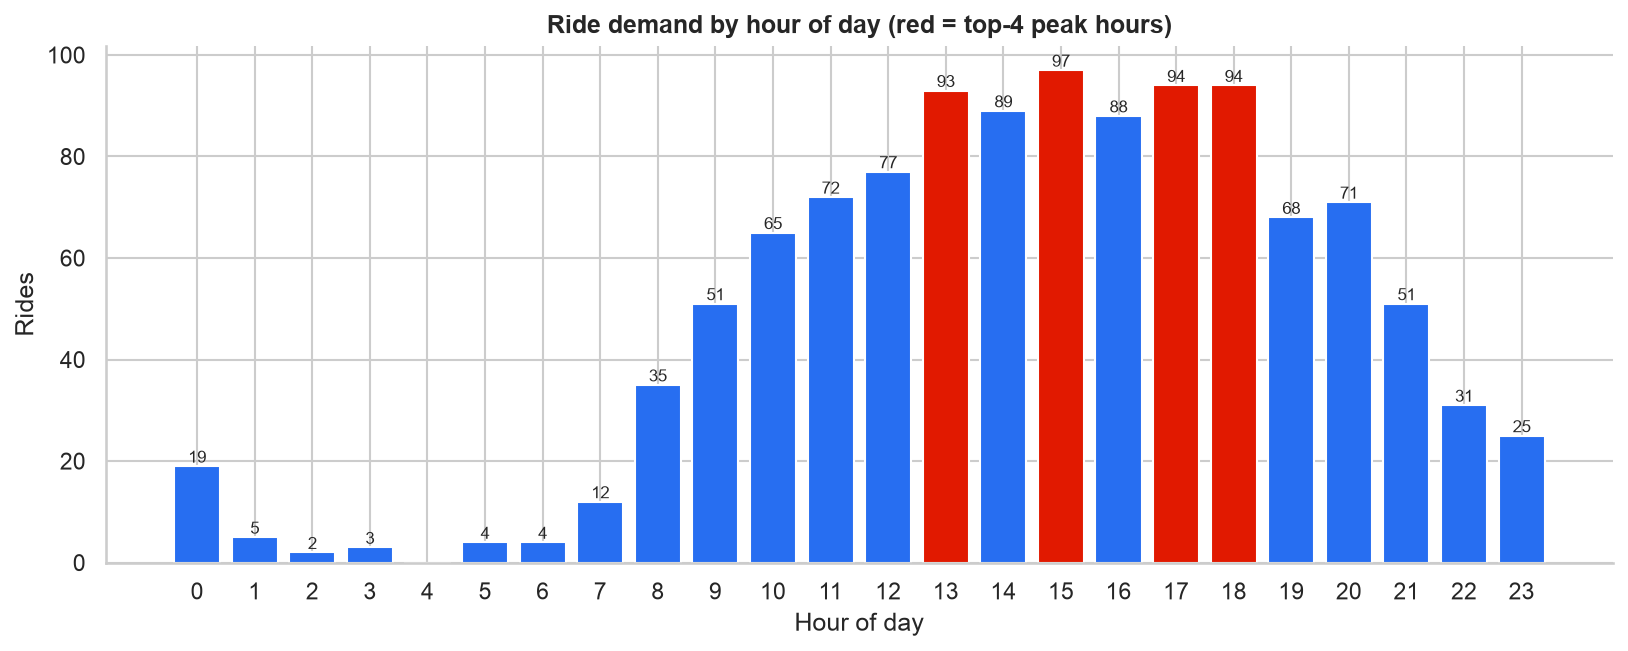

In [11]:
show(FIG / '01_rides_by_hour.png')

### 4.2 Day of week
**Friday** is clearly the busiest day; weekends are not quieter than mid-week.

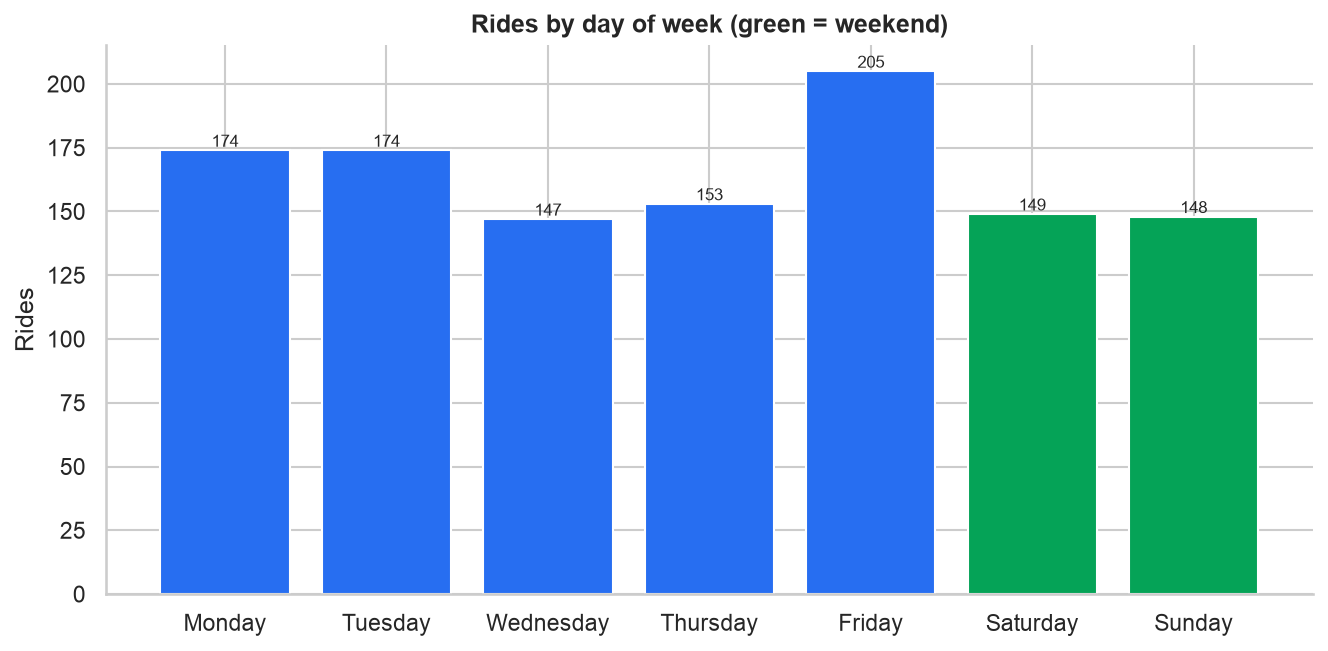

In [12]:
show(FIG / '02_rides_by_weekday.png')

### 4.3 Monthly trend

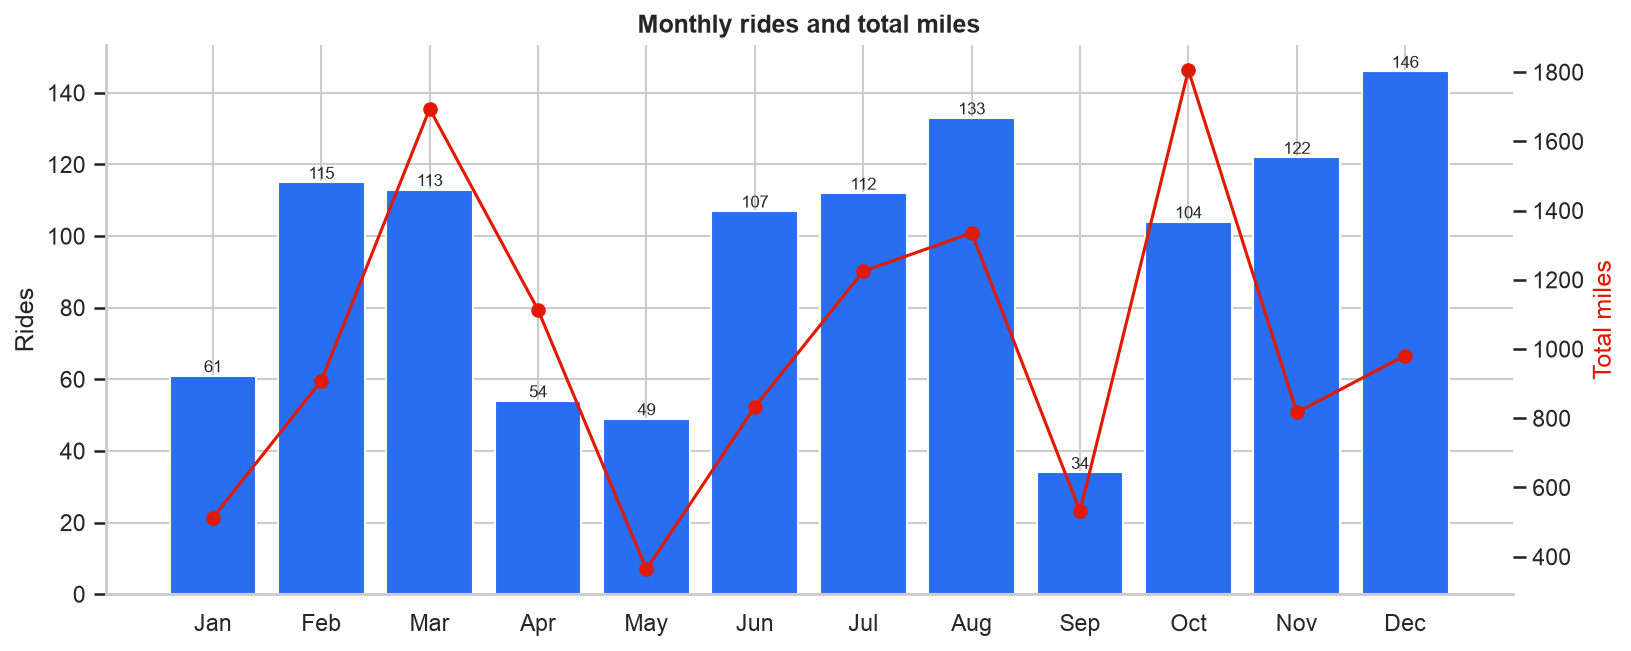

In [13]:
show(FIG / '03_rides_by_month.png')

### 4.4 Heatmaps
Friday late morning and early afternoon are the hottest slots.

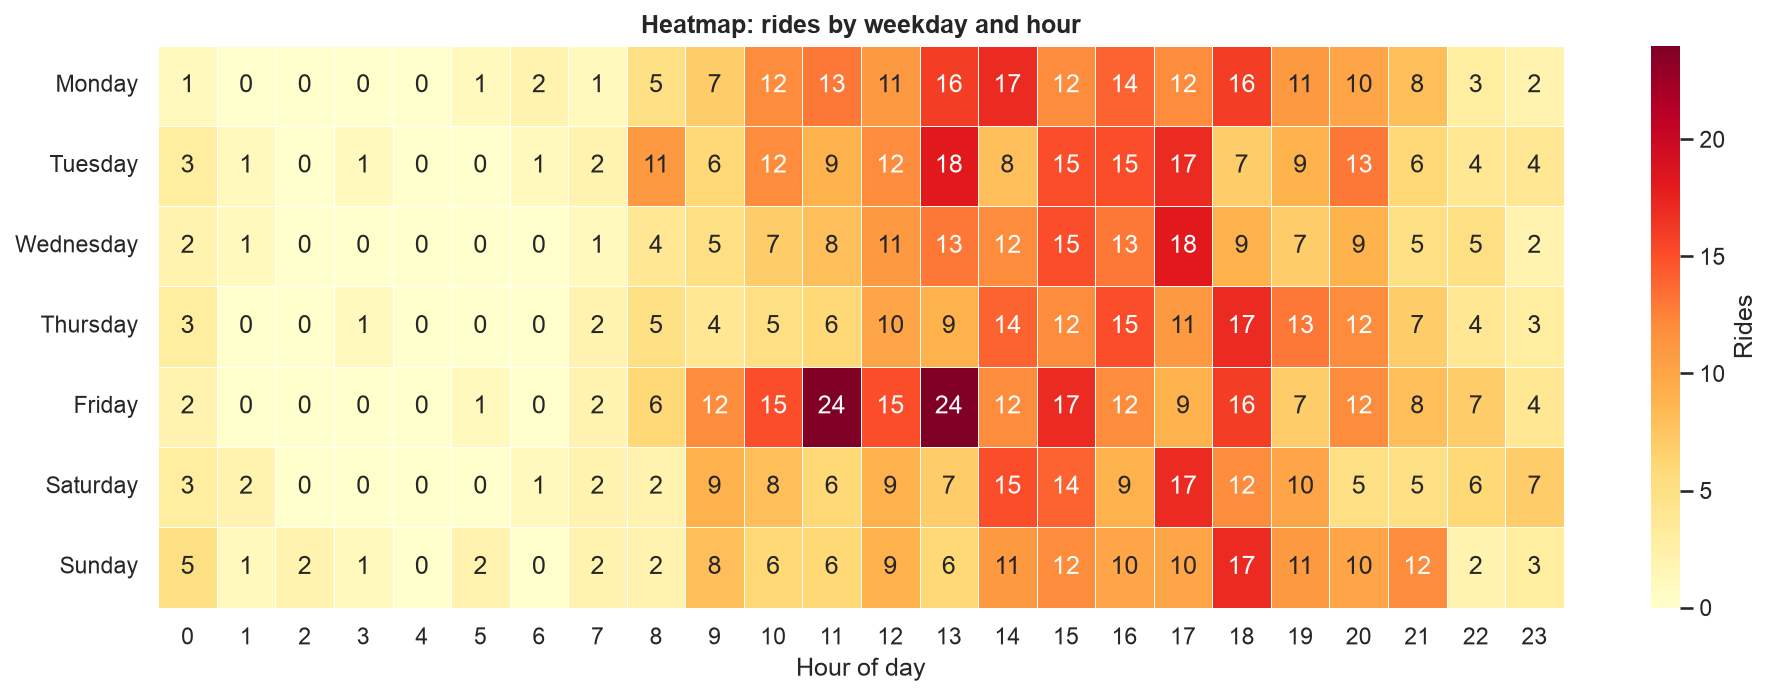

In [14]:
show(FIG / '04_heatmap_weekday_hour.png')

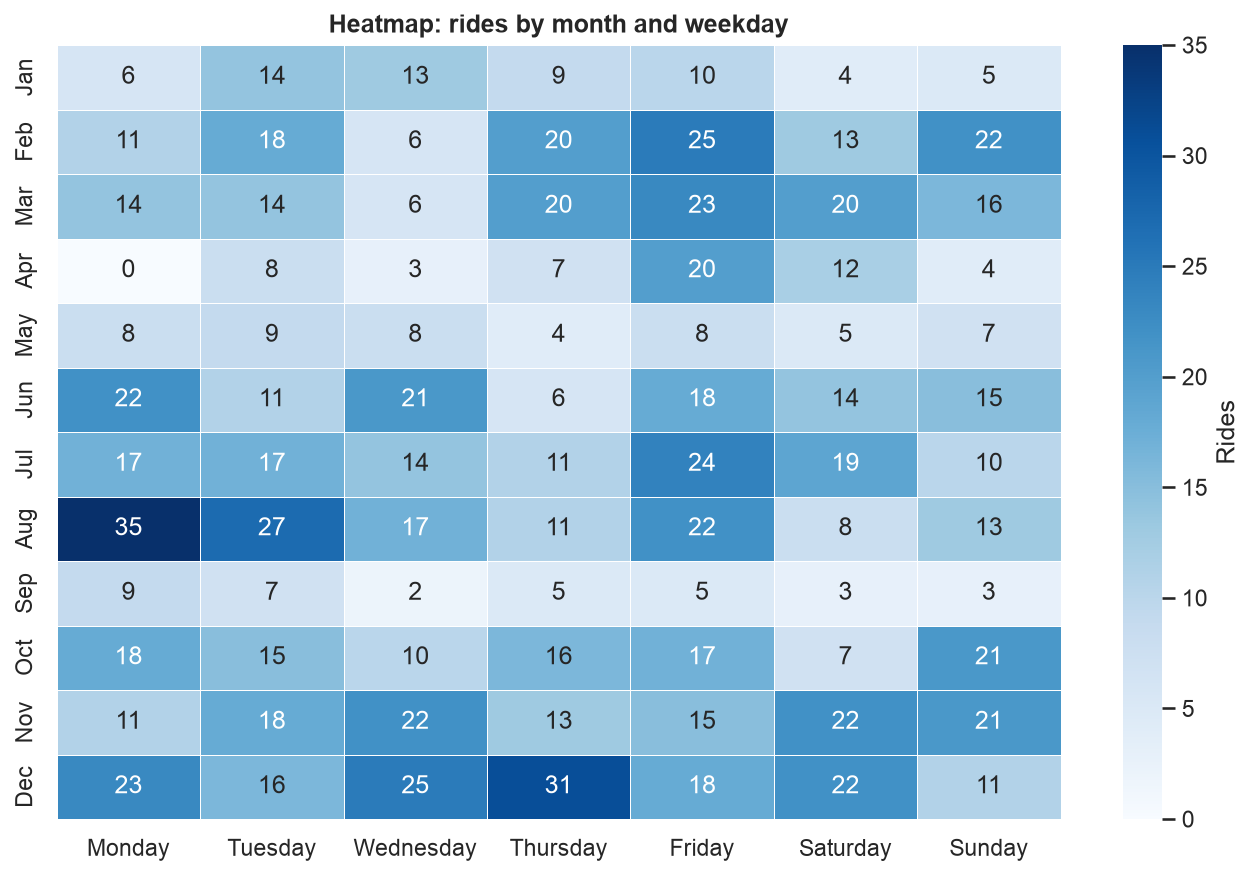

In [15]:
show(FIG / '05_heatmap_month_weekday.png')

### 4.5 Time series of daily demand
Demand comes in bursts (travel periods) with quiet spells in April-May and September.

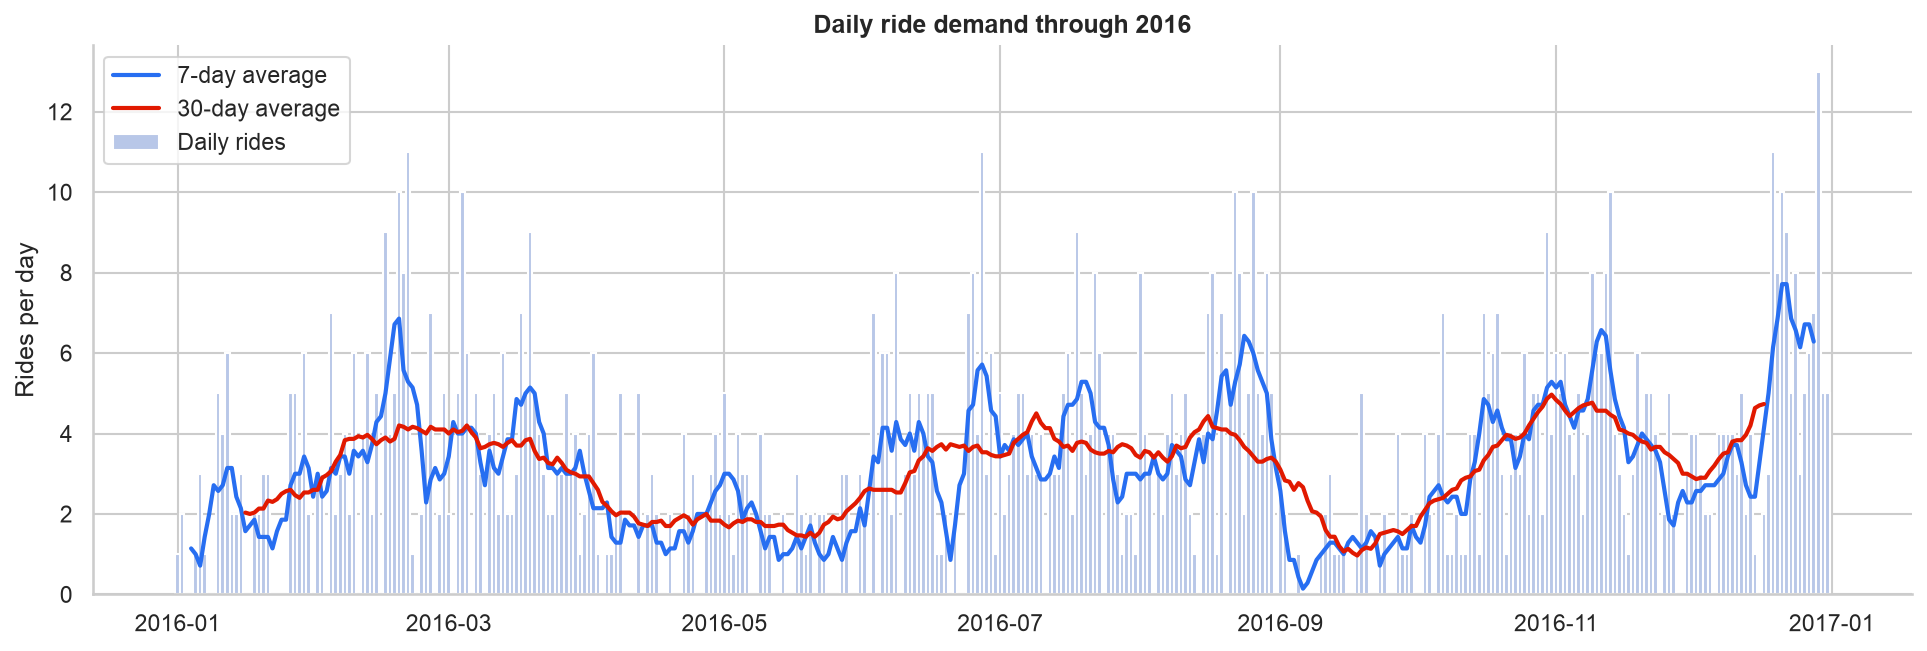

In [16]:
show(FIG / '06_daily_demand_timeseries.png')

### 4.6 Category, purpose and locations

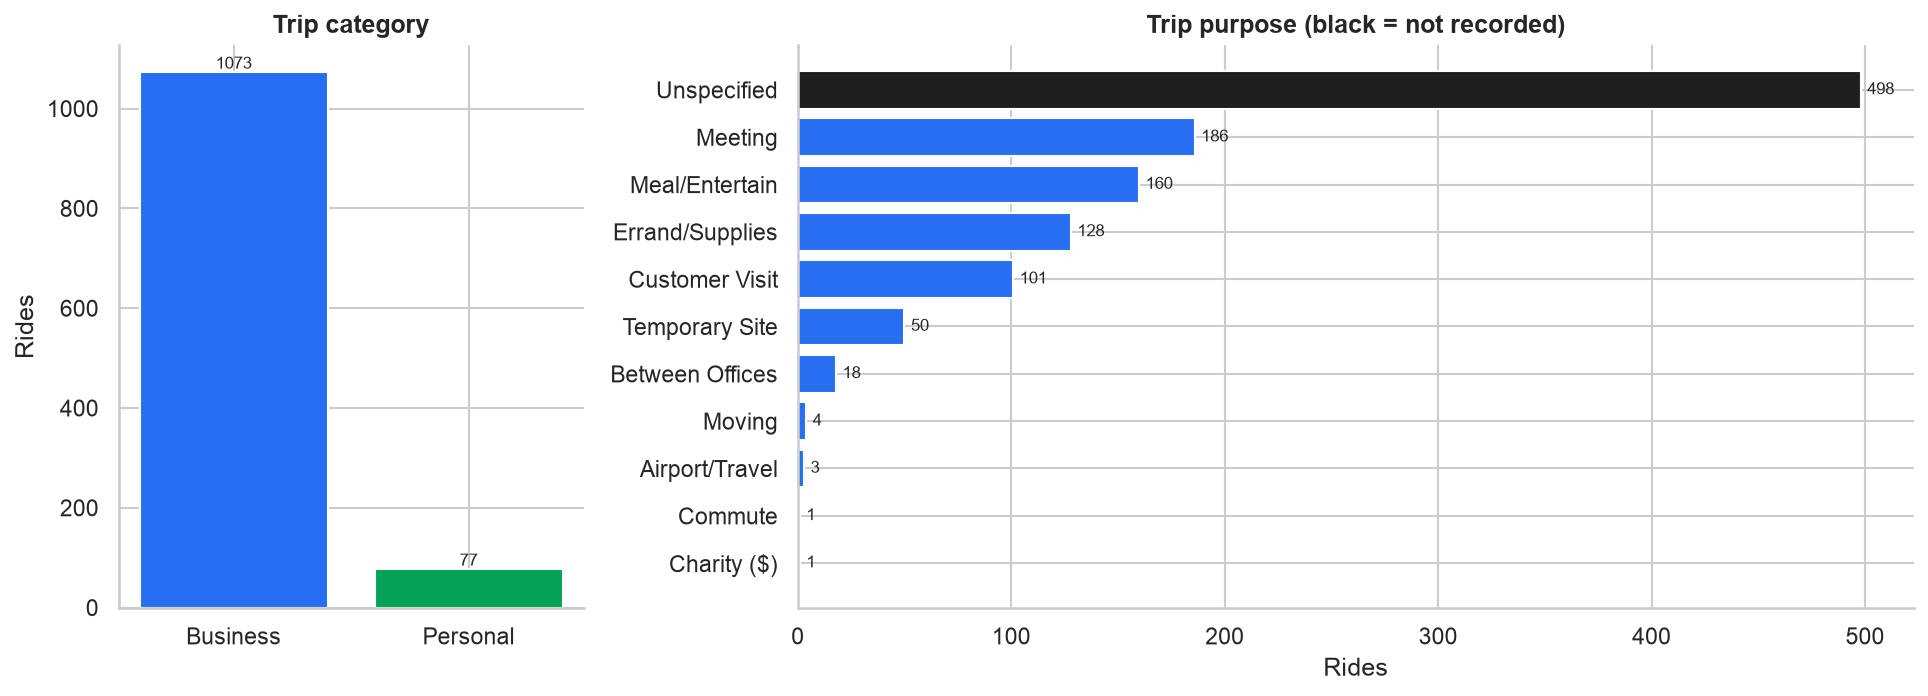

In [17]:
show(FIG / '07_category_and_purpose.png')

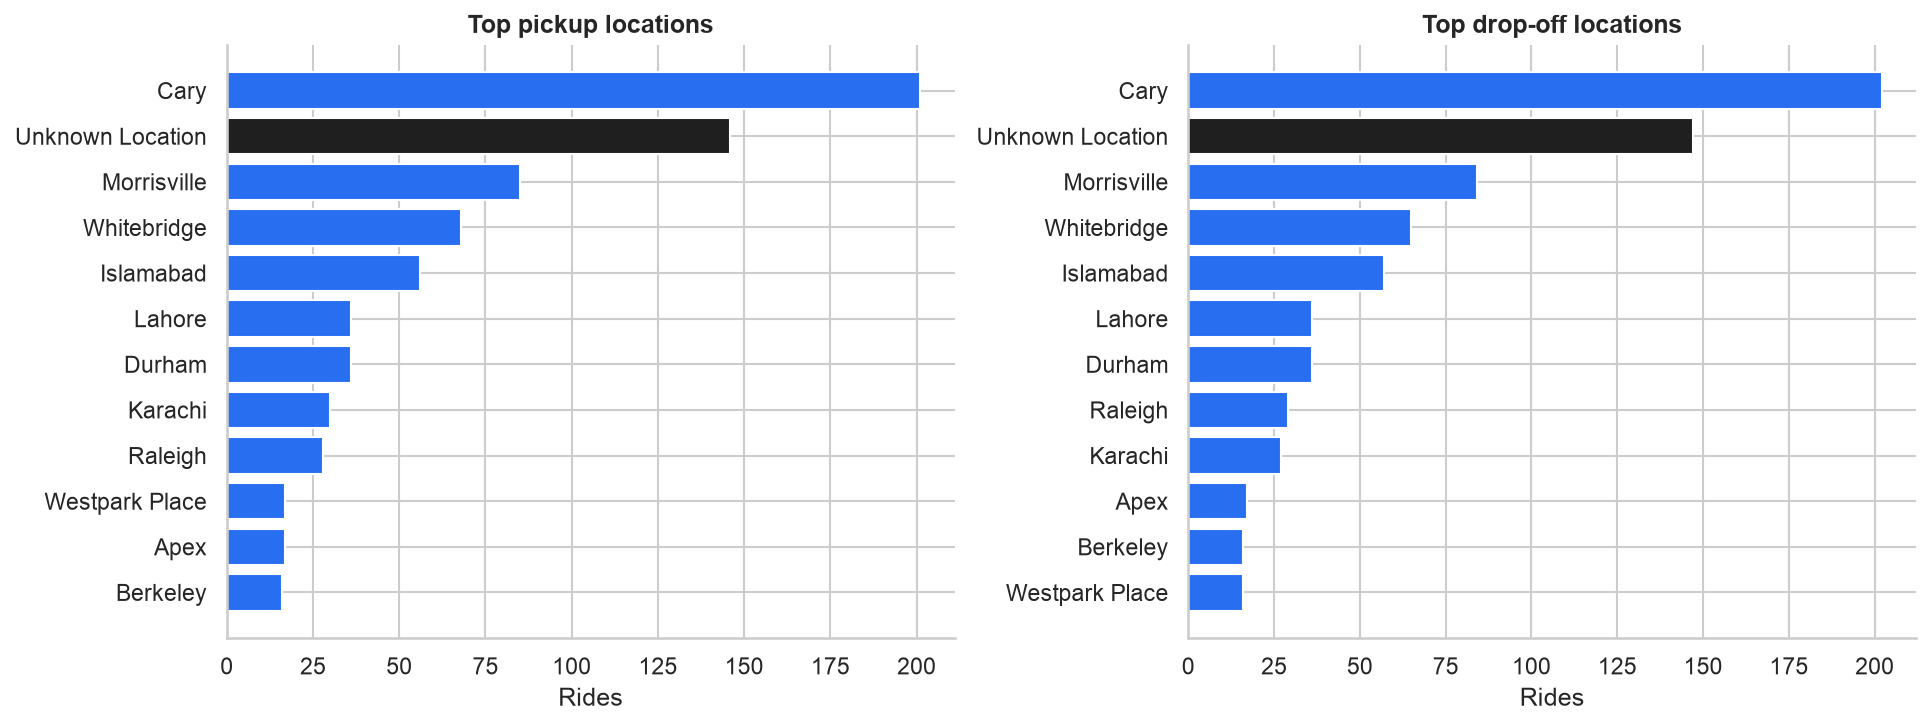

In [18]:
show(FIG / '08_top_locations.png')

### 4.7 Distance, duration and anomalies

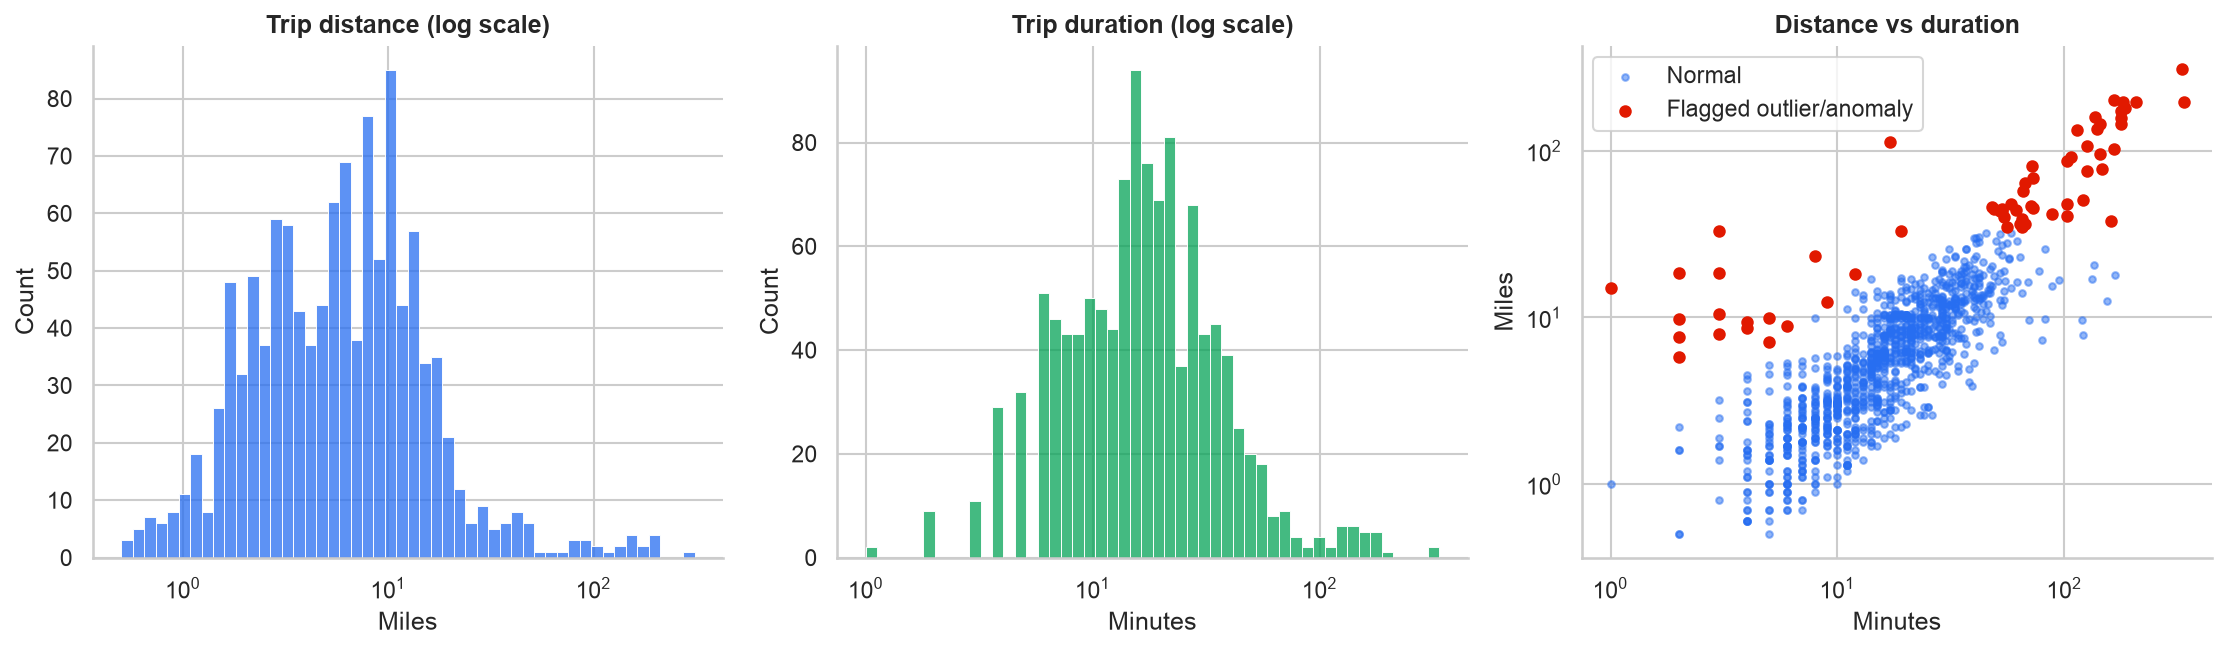

In [19]:
show(FIG / '09_distance_duration_anomalies.png')

In [20]:
df.loc[df.is_speed_anomaly, ['start_time','start_location','stop_location','miles','duration_min','speed_mph']].round(1).head(10)

/var/folders/lx/2q001qb16rsbnz7xk8kgfnwm0000gn/T/ipykernel_29735/2236632631.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df.loc[df.is_speed_anomaly, ['start_time','start_location','stop_location','miles','duration_min','speed_mph']].round(1).head(10)


,start_time,start_location,stop_location,miles,duration_min,speed_mph
6,2016-01-06 17:30:00,West Palm Beach,Palm Beach,7.1,5.0,85.2
121,2016-02-18 08:19:00,Unknown Location,Unknown Location,23.5,8.0,176.2
126,2016-02-19 09:02:00,Unknown Location,Unknown Location,18.3,12.0,91.5
335,2016-04-28 13:30:00,Raleigh,Cary,32.8,19.0,103.6
375,2016-05-18 13:00:00,Morrisville,Raleigh,7.6,2.0,228.0
524,2016-07-07 10:27:00,Morrisville,Cary,8.9,6.0,89.0
751,2016-09-11 09:51:00,Unknown Location,Unknown Location,8.6,4.0,129.0
752,2016-09-11 21:40:00,Unknown Location,Unknown Location,9.8,2.0,294.0
759,2016-09-18 18:07:00,Unknown Location,Unknown Location,9.4,4.0,141.0
770,2016-09-27 08:33:00,Unknown Location,Unknown Location,5.8,2.0,174.0


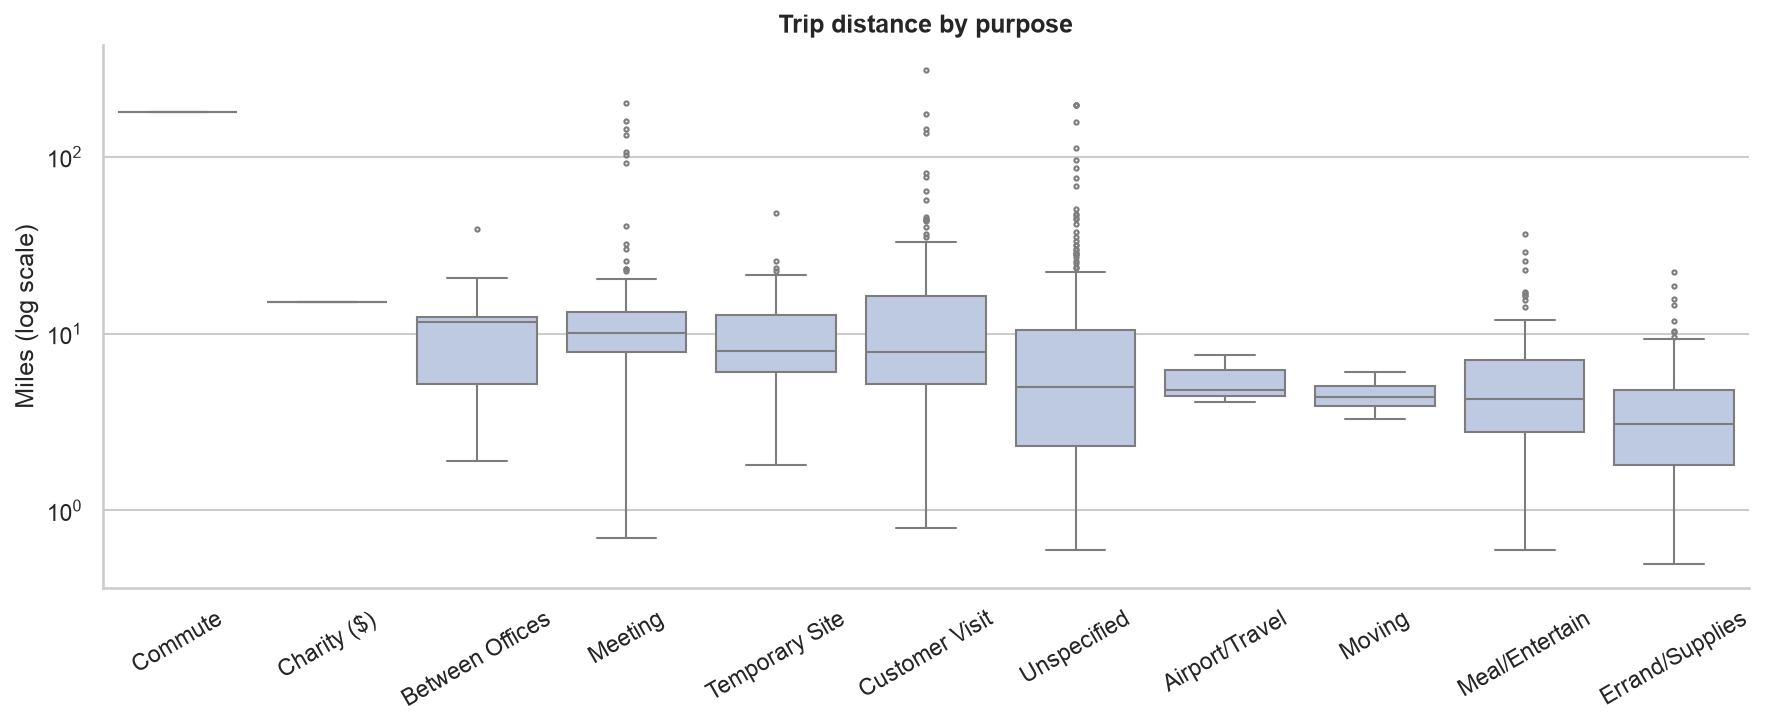

In [21]:
show(FIG / '10_distance_by_purpose.png')

### 4.8 Fare trends (estimated)

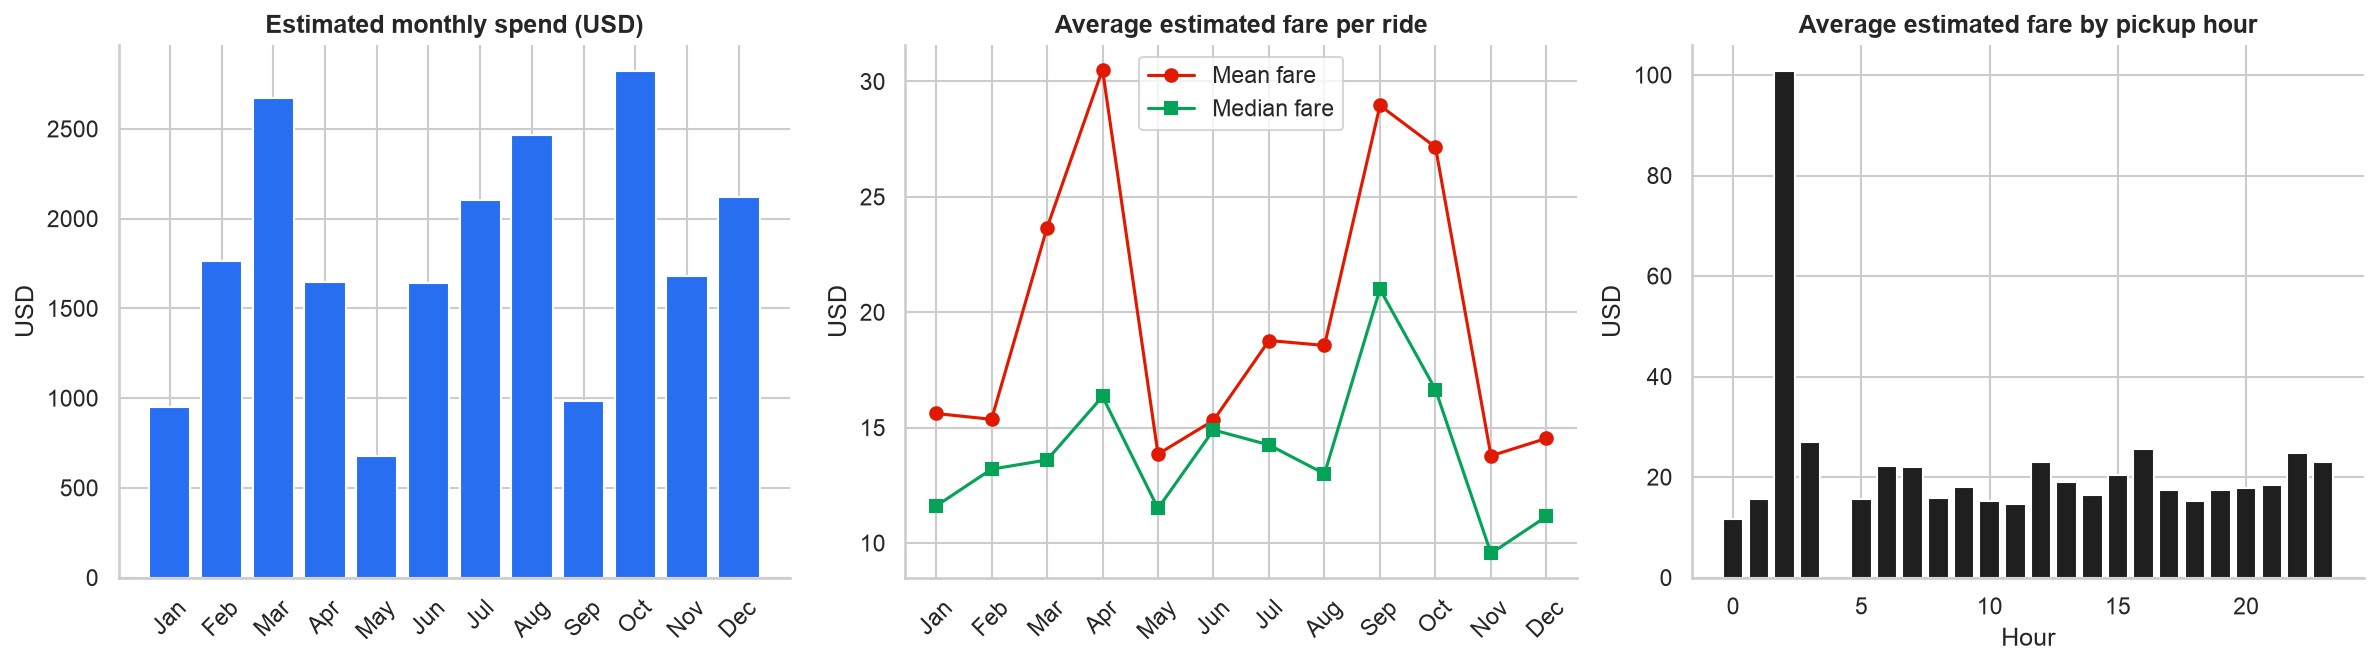

In [22]:
show(FIG / '11_fare_trends.png')

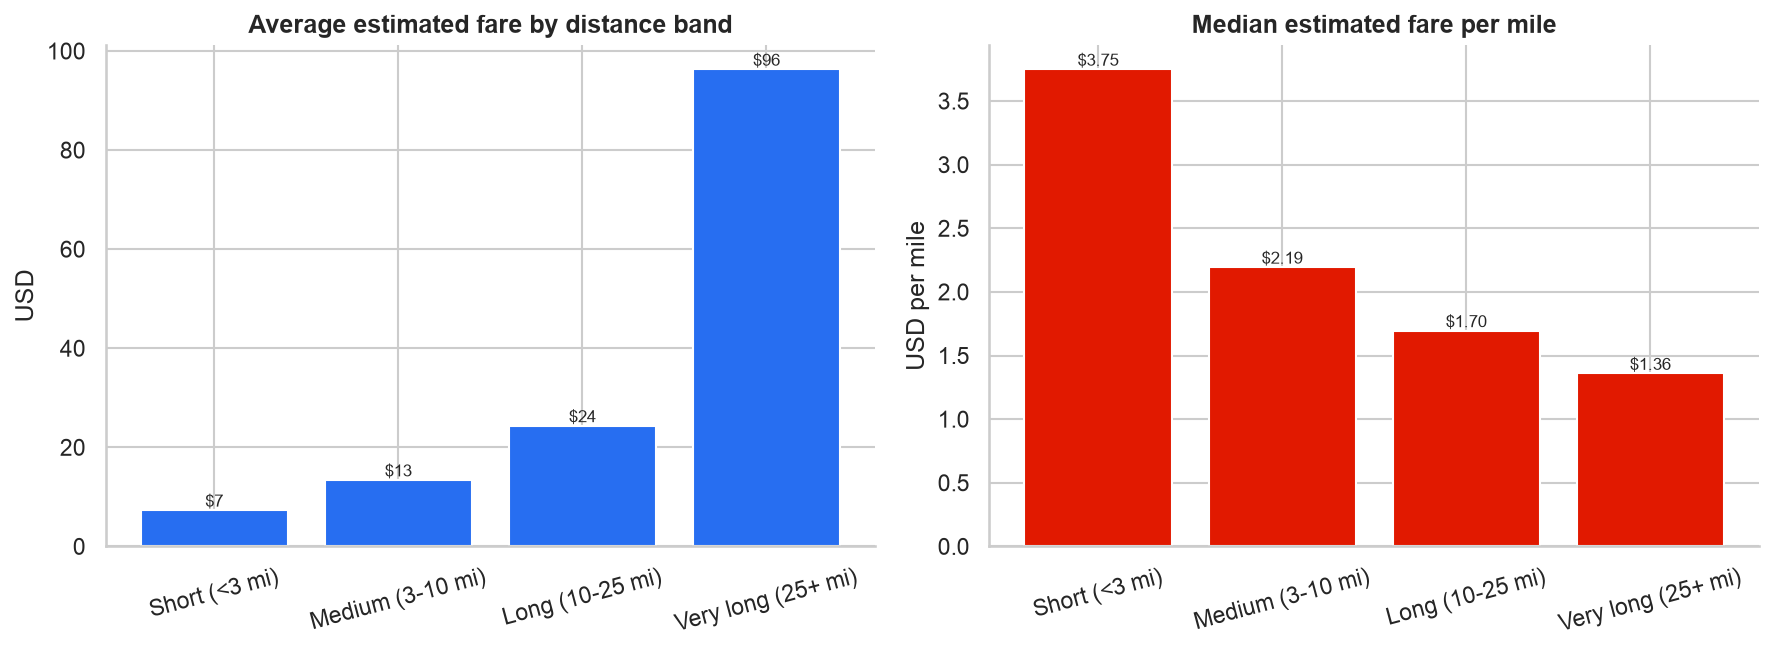

In [23]:
show(FIG / '12_fare_by_distance_band.png')

## 5. Ride-demand forecasting

**Target:** number of rides tomorrow.  **Features:** calendar (weekday, month, day of month, weekend) and past demand (lags 1/2/7/14 days, 7- and 28-day rolling mean/std, zero-ride days in last week). Every lag uses only past days.

**Split:** train Jan-Oct, test Nov-Dec (time-ordered, no shuffling). TimeSeriesSplit CV on the training set.

**Baselines:** yesterday's count, same day last week, 7-day average. A model is only useful if it beats these.

In [24]:
FEATURES

['dayofweek',
 'is_weekend',
 'month',
 'dayofmonth',
 'lag_1',
 'lag_2',
 'lag_7',
 'lag_14',
 'roll_mean_7',
 'roll_mean_28',
 'roll_std_7',
 'zero_days_last_7']

In [25]:
fc = run_forecasting(daily)
print('Train:', fc['train_period'])
print('Test :', fc['test_period'])
pd.DataFrame(fc['metrics']).T

Train: 2016-01-29 to 2016-10-31 (277 days)
Test : 2016-11-01 to 2016-12-31 (61 days)


,MAE,RMSE,R2,type,CV_MAE_train
Naive (yesterday),2.082,2.731,0.016,baseline,NaN
Seasonal naive (same day last week),2.574,3.292,-0.429,baseline,NaN
7-day average,2.126,2.735,0.014,baseline,NaN
Ridge Regression,1.938,2.617,0.097,ml,2.483
Random Forest,2.124,2.853,-0.073,ml,2.044
Gradient Boosting,2.479,3.131,-0.293,ml,2.421


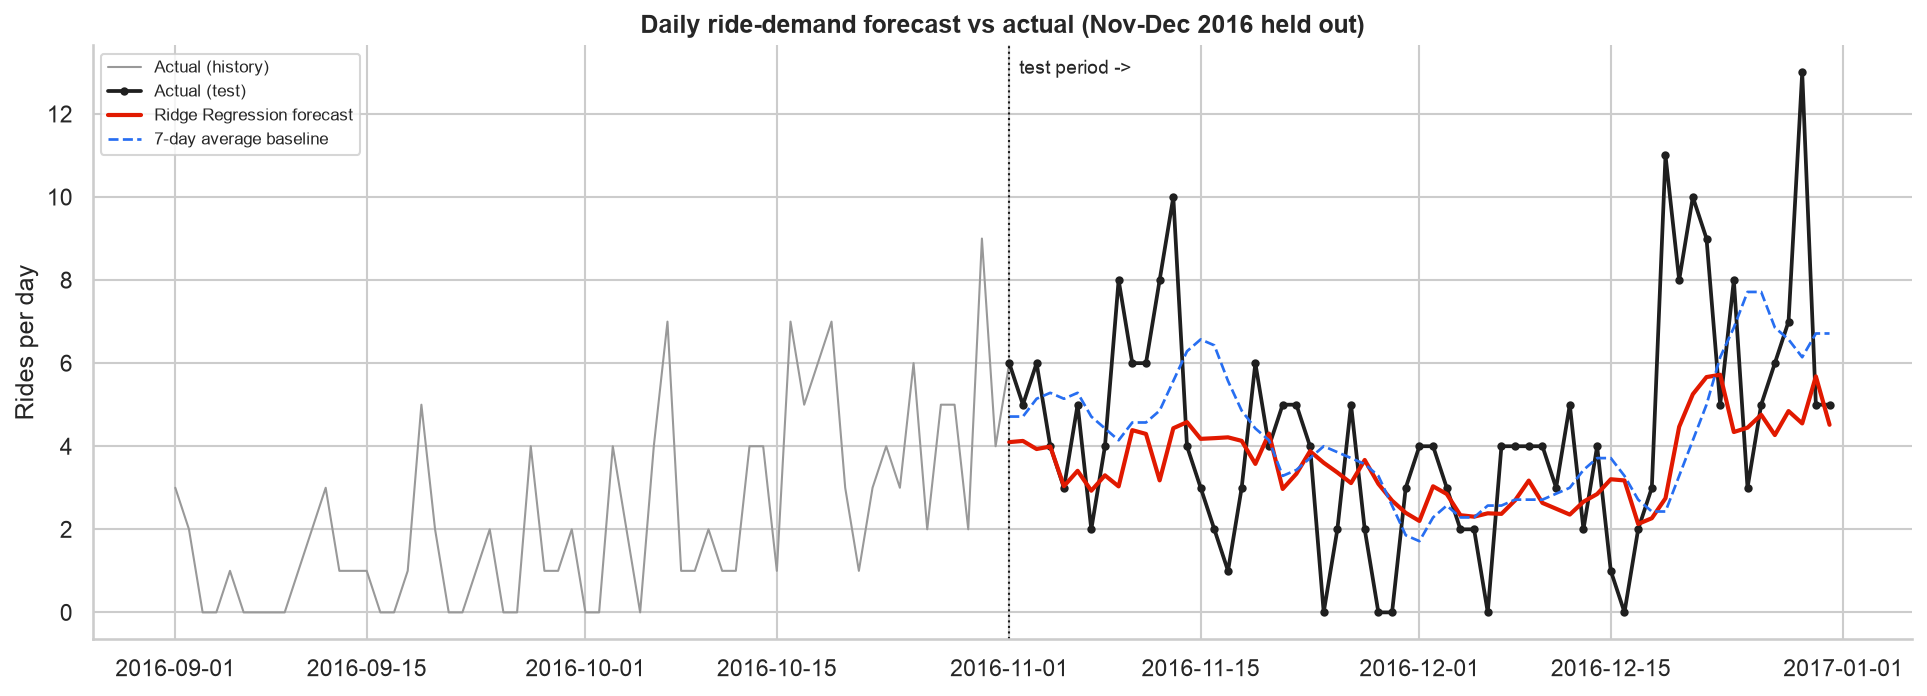

In [26]:
viz.forecast_plot(daily, fc['predictions'], fc['best_model'], FIG)
viz.model_comparison(fc['metrics'], FIG)
viz.feature_importance(fc['feature_importance'], FIG)
plt.close('all')
show(FIG / '13_demand_forecast.png')

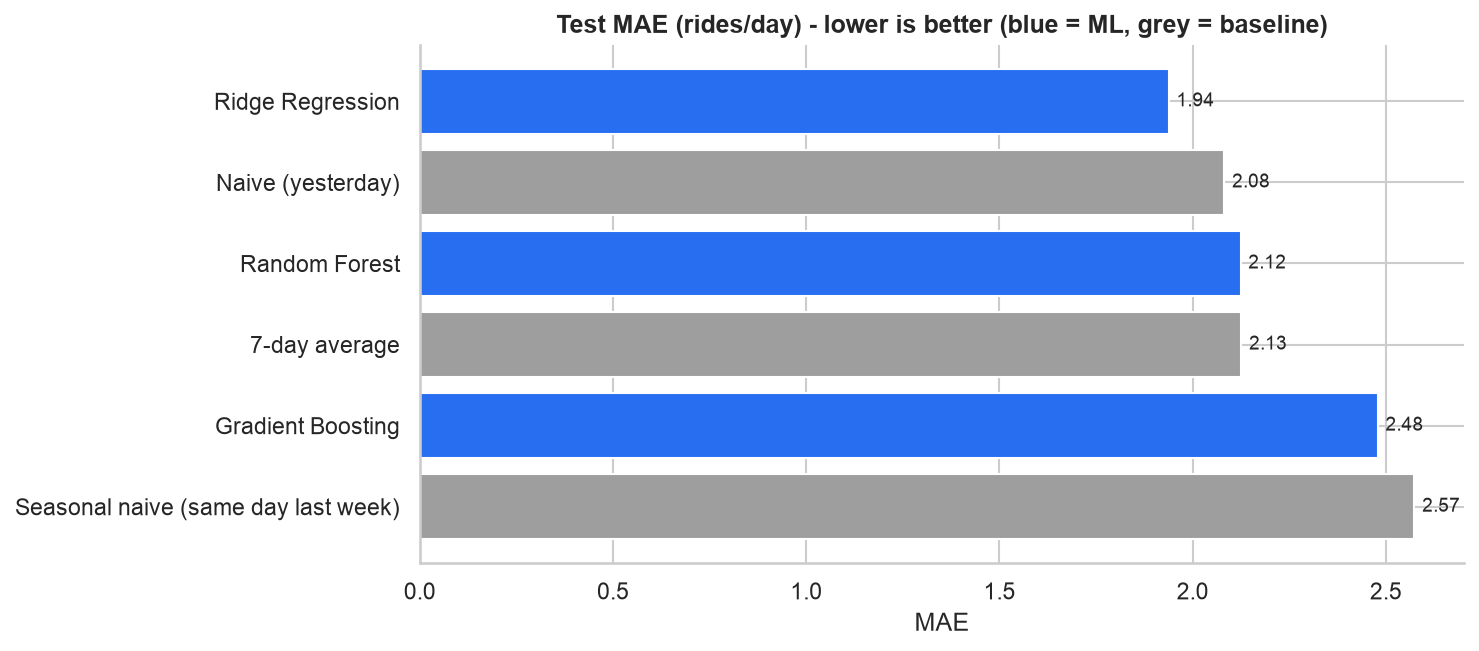

In [27]:
show(FIG / '14_model_comparison.png')

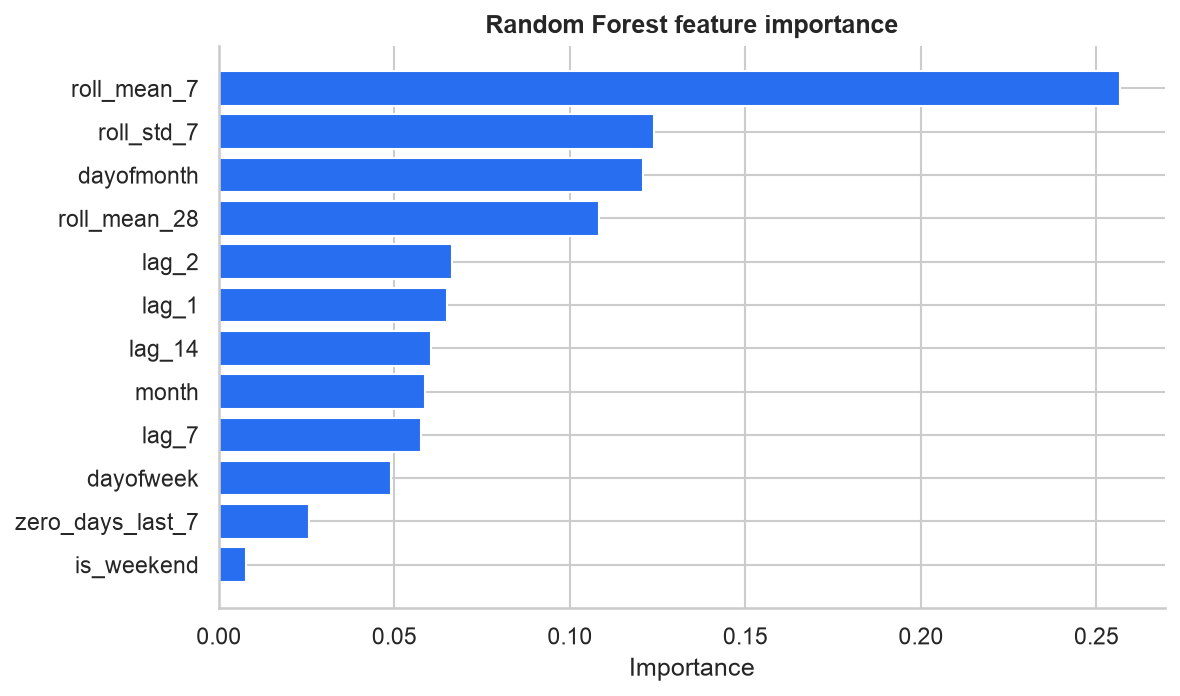

In [28]:
show(FIG / '15_feature_importance.png')

### Why not predict trip miles?
The first draft (`notebooks/early_work/`) predicted miles from hour/day/month. Re-running it shows it is no better than always guessing the median, because trip length depends on the destination, not the time of day:

In [29]:
miles_regression_check(df)

{'model': {'MAE': 10.234, 'RMSE': 24.835, 'R2': 0.012},
 'median_baseline': {'MAE': 9.21, 'RMSE': 25.722, 'R2': -0.06}}

## 6. Conclusions

See the README for the full list of insights, challenges, improvements and business applications. In short: demand peaks 1-6 pm and on Fridays, 93% of trips are business, a few long inter-city trips account for 39% of all miles, and short trips cost the most per mile. The best demand model (Ridge regression) beats the naive baselines, but daily rides for a single rider are noisy, so forecasts are best used for smoothed demand levels rather than exact daily counts.